In [1]:
import os
import tensorflow as tf
from tqdm import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import keras

from tensorflow.keras import layers, models
from keras.models import Sequential, Model
from loss import custom_loss
from keras.losses import MeanSquaredError
from keras.layers import *
from keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose
from qkeras import *

import DAE_DataGenerator
import importlib

importlib.reload(DAE_DataGenerator)
from DAE_DataGenerator import OptimizedDataGenerator as DAE_DG
#from dataprep import *
from OptimizedDataGenerator_v2 import OptimizedDataGenerator as NewDG
from loss import *
import models
importlib.reload(models)
from models import *
# from models import var_network
# from models import CreateModel

from dataset_utils import add_noise

import matplotlib.pyplot as plt
pi = 3.14159265359

maxval=1e9
minval=1e-9

2026-07-01 13:41:53.661389: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
'''Load data for DAE training'''
# tfrecords_dir_val = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_80eN_catgoricalOut"
# tfrecords_dir_train = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_80eN_catgoricalOut"

# tfrecords_dir_val = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_80eN_catgoricalOut_lowThreshTarget"
# tfrecords_dir_train = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_80eN_catgoricalOut_lowThreshTarget"

tfrecords_dir_val = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_80eN_catgoricalOut_Target_0_30_856"
tfrecords_dir_train = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_3srCI_80eN_catgoricalOut_Target_0_30_856"


validation_generator = DAE_DG(
    load_from_tfrecords_dir = tfrecords_dir_val,
)
training_generator = DAE_DG(
    load_from_tfrecords_dir = tfrecords_dir_train,
)



Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_3srCI_80eN_catgoricalOut_Target_0_30_856/metadata.json


Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_3srCI_80eN_catgoricalOut_Target_0_30_856/metadata.json


In [3]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.optimizers import Adam
import keras
from keras.models import Sequential, Model
from keras.layers import *
from keras.utils import Sequence
from keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose
# from qkeras import *

from models import var_network


def get_min_max(training_generator, validation_generator):
    tmax,tmin = [training_generator.dataset_max, training_generator.dataset_min]
    vmax,vmin = [validation_generator.dataset_max, validation_generator.dataset_min]
    return min(tmin, vmin), max(tmax, vmax)
    
def encoder_network(shape, var, kernel_size=3, n_filters=5, pool_size=2):
    var = QSeparableConv2D(
        n_filters, kernel_size, padding = 'same',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)
    var = AveragePooling2D(
        pool_size=(pool_size, pool_size), 
        strides=pool_size, 
        padding="same", 
        data_format='channels_last',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)
    var = QConv2D(
        n_filters,kernel_size, padding = 'same',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)  
    var = AveragePooling2D(
        pool_size=(pool_size, pool_size), 
        strides=pool_size, 
        padding="same", 
        data_format='channels_last',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)  
    return var

def decoder_network(shape, var, kernel_size=3, n_filters=5, pool_size=2):
    var = Conv2DTranspose(
        n_filters, 1, padding = 'same', strides = pool_size,
    )(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)
    var = Conv2DTranspose(
        n_filters, kernel_size,
        strides = pool_size,
        padding="same",
    )(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)    
    var = Conv2D(shape[-1], (pool_size, pool_size), padding="same")(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)
    # if input_quant is not None:
    #     # quantize = lambda x: quantize_manual(x, charge_levels = input_quant, quant_values =[0,1,2,3])
    #     quantize = lambda x: hard_quantize(x, levels = [0.0,1.0,2.0,3.0], thresholds = input_quant)
    #     var = Lambda(function=quantize, dtype=tf.float32)(var)
    return var
    
def Qdecoder_network(shape, var, kernel_size=3, n_filters=5, pool_size=2):
    var = Conv2DTranspose(
        n_filters, 1, padding = 'same', strides = pool_size,
    )(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)
    var = Conv2DTranspose(
        n_filters, kernel_size,
        strides = pool_size,
        padding="same",
    )(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)    
    var = Conv2D(shape[-1], (pool_size, pool_size), padding="same")(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)
    var = Flatten()(var)
    var = Dense(math.prod(shape)*8, activation='softmax')(var)
    var = Reshape((*shape, 8))(var)
    return var

def CreateSQAutoEncoder(shape, n_filters=5, pool_size=2, conv_kernel_size=3, decoder_filters = 5, mean_filter=False, thresh = False, xrange = None):
    x_base = x_in = Input(shape)
    x_base = SoftQuantizeLayer(
        n_bits=3,
        initial_thresholds = [0.5,1,2,3,4,5,6],#[247.80, 668.41, 1662.85]
        initial_levels = [0.0, 1.0, 2.0, 3.0, 4.0, 5., 6., 7.
                         ],
        # initial_range=[-1.0, 1.0],    
        trainable_levels=False,        
        trainable_thresholds=True,   
        # threhsold_offset = 80,
        initial_k=1.0,                
        trainable_k=False,             
        name='soft_quantizer_output'  
    )(x_base)
    stack = encoder_network(shape, x_base, n_filters=n_filters, pool_size=pool_size, kernel_size = conv_kernel_size)
    stack = Qdecoder_network(shape, stack, n_filters=decoder_filters, pool_size=pool_size, kernel_size = conv_kernel_size)
    print(type(stack))
    if xrange is not None:
        # def scale(x, xrange = [-1,1]):
        #     return x*xrange[1] if x>=0 else x*abs(xrange[0])
        # scale_pn = lambda x: scale(x, xrange = xrange)
        # stack = Lambda(function = scale_pn)(stack)
        def scaled_function(data):
            return asymmetric_scaling(data, positive_scale=xrange[1], negative_scale=abs(xrange[0]))
        stack = Lambda(function = scaled_function)(stack)
    model = Model(inputs=x_in, outputs=stack)
    return model

In [3]:
'''reconstruct the SQuautoencoder from weights'''
import models
import loss
importlib.reload(models)
importlib.reload(loss)
from loss import *
from models import *
from SoftQuantizeLayer import SoftQuantizeLayer
from AnnealingScheduler import AnnealingScheduler
import math

# weights_path = './SQ_DAE/model-e12251df-SQDAE_2bit_80eN_SSIM_LogScaled_QRange0to3_80eThreshOffset-checkpoints/'
# weights_path = './SQ_DAE/model-11644ab3-SQDAE_2bit_80eN_CategoricalOutput_lowThreshTarget-checkpoints/'
# weights_path = './SQ_DAE_regression/model-7f27e133-SQDAE_regression_CategoricalLowThreshTarget-checkpoints/'

# weights_path = './SQ_DAE/model-5d8a15ee-SQDAE_Categorical_v2_2bit_80eN_Target_0_30_856-checkpoints/'
# weights_path = './SQ_DAE/model-966a30e9-SQDAE_Categorical_2bit_80eN_Target_0_7_23_134_404_867_1748-checkpoints/'
# weights_path = './SQ_DAE/model-c355fe4b-SQDAE_Categorical_3bit_80eN_Target_0_7_23_134_404_867_1748-checkpoints'
# weights_path = './SQ_DAE/model-dce0cb7a-SQDAE_Categorical_2bit_0eN_Target_0_7_23_134_404_867_1748-checkpoints/'
# weights_path = './SQ_DAE/model-20c437b9-SQDAE_Conv2D_Categorical_2bit_0eN_Target_0_30_856-checkpoints/'
weights_path = './SQ_DAE/model-9038a7c9-SQDAE_Conv2D_Categorical_2bit_80eN_Target_0_30_856-checkpoints/'

base_dir = weights_path
checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
#training_cp_path = os.path.join(base_dir, 'training_log.csv')
#training_history = pd.read_csv(training_cp_path)

print(f"Loading model from {latest_checkpoint}")


Loading model from ./SQ_DAE/model-9038a7c9-SQDAE_Conv2D_Categorical_2bit_80eN_Target_0_30_856-checkpoints/weights.95-t172667.9219-v172195.4375.hdf5


In [4]:
'''Load SQAutoencoder_conv2D from weights'''
model=CreateSQAutoencoder_Conv2DSlim((16,16,2), n_filters=5, pool_size=3,
                        decoder_filters = 128, initial_thresholds=[10,80,800], 
                                     OutBits = 2, conv_kernel_size = 3)

model.load_weights(latest_checkpoint)

2026-07-01 13:42:53.147777: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-07-01 13:42:53.187575: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-07-01 13:42:53.187986: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-07-01 13:42:53.189054: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropri

In [44]:
'''Load SQ DAE from weights'''
model=CreateSQAutoEncoder((16,16,2), n_filters=5, pool_size=2, conv_kernel_size = 3, 
                        decoder_filters = 128, 
                        # input_quant = [0.2,0.6,3.0],
                        xrange = None
                       )
model.load_weights(latest_checkpoint)

<class 'keras.engine.keras_tensor.KerasTensor'>


In [12]:
'''Load SQ_DAE_regression from weights'''
DAE=CreateSQAutoEncoder((16,16,2), n_filters=5, pool_size=2, conv_kernel_size = 3, 
                        decoder_filters = 128, 
                        # input_quant = [0.2,0.6,3.0],
                        xrange = None
                       )
layer_name = DAE.layers[9].name
print(layer_name)
encoder = Model(inputs=DAE.input, outputs=DAE.get_layer(layer_name).output)
encoder.trainable = False
x_in = encoder.input
lat_shape = encoder.output.shape
dense_net = var_network(encoder.output, hidden=16, output=14)
model = Model(inputs=x_in, outputs=dense_net)

model.load_weights(latest_checkpoint)#Create Plots

<class 'keras.engine.keras_tensor.KerasTensor'>
q_activation_31


In [25]:
noise = np.random.normal(0,  80, size = (100,16,16,2))
print(noise.shape, noise[:,:,1])

(100, 16, 16, 2) [[[-134.87811997   22.37700787]
  [ 101.4561223    36.11473301]
  [  49.59945331   41.72073557]
  ...
  [ 107.41930999  -47.13104476]
  [ -43.61000635   -3.23440558]
  [ -87.85348196   66.25611892]]

 [[ -85.73088923   55.03616536]
  [ -61.42435767  -22.31930779]
  [ -88.82434326  112.66133481]
  ...
  [  82.17055355  -52.44054693]
  [  63.8172917   -56.47663208]
  [  43.51032963    0.95030247]]

 [[ -50.88416899   97.09719197]
  [-155.47332689   24.15748249]
  [  31.78481201  -35.63694177]
  ...
  [ -42.10636682    6.38911498]
  [-100.42850803  191.76580187]
  [ -15.39910388  -63.44582001]]

 ...

 [[ -22.18096943  -30.71005235]
  [  90.71329185   92.1277654 ]
  [   3.81736289   90.04097812]
  ...
  [  11.86617144   18.55542023]
  [ 110.27002391  -17.35209638]
  [ -25.5203753   -42.9987734 ]]

 [[  61.2923801  -100.49544726]
  [ -36.40330228   -6.40276999]
  [  33.73636365 -130.89548619]
  ...
  [-121.95452625   35.92668022]
  [ -77.16956047   14.91695929]
  [   2.914

4/4 [==============================] - 0s 3ms/step
<class 'numpy.ndarray'>


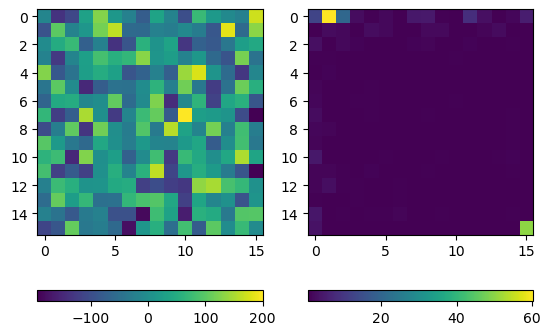

In [33]:
# predicts test data
p_test = model.predict(noise)
print(type(p_test))

def inverse_logStandardize(x, logmin= -12.4654, logmax = 16.6213):
    pos = x>0
    neg = ~pos
    x[pos] = x[pos]*logmax
    x[neg] = x[neg]*logmin
    x = np.sign(x)*np.log(2)*np.exp(abs(x))
    return(x)

# logmin,logmax = -12.465420526441807, 16.62130959403679


fig,ax = plt.subplots(1,2)

a = ax[0].imshow(noise[0,:,:,0])
fig.colorbar(a, orientation = 'horizontal',)

a = ax[1].imshow(inverse_logStandardize(p_test[0,:,:,0]))
fig.colorbar(a, orientation = 'horizontal',)

4/4 [==============================] - 0s 3ms/step
[[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 1 1 1 1 0 0 0 0 0 0]
 [0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]]


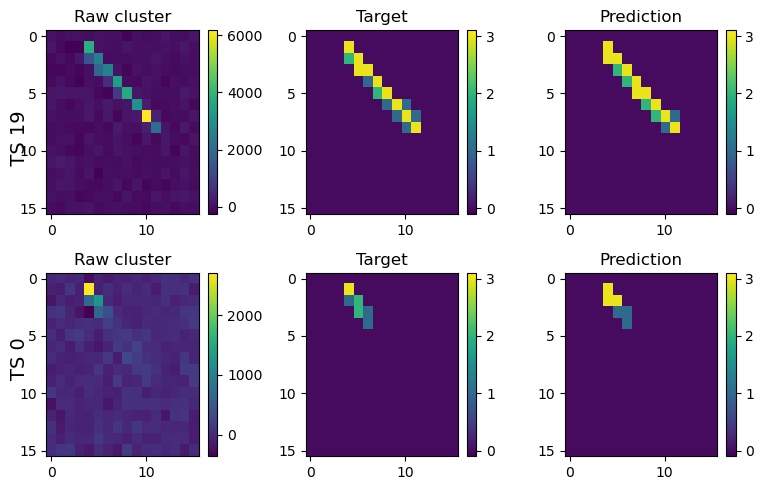

In [37]:
test_cluster = validation_generator[0][0][:100][:,:,:]
true_cluster = np.argmax(validation_generator[0][1][:100][:,:,:],axis = -1)
p_out = np.argmax(model.predict(test_cluster), axis=-1)
print(np.argmax(p_out[0,:,:,:], axis=-1))

N = 29
fig, ax = plt.subplots(2, 3, figsize=(8,5))
ts = [1,0]
vmin, vmax = [-0.1, 3.1]

for i, t in enumerate(ts):

    a=ax[i,2].imshow(p_out[N,:, :,t], vmin = vmin, vmax = vmax, aspect='auto')
    ax[i,2].set(title = 'Prediction')
    fig.colorbar(a, ax = ax[i,2], orientation = 'vertical',)
    
    a=ax[i,0].imshow(test_cluster[N, :, :,t], aspect='auto')
    ax[i,0].set(title = 'Raw cluster')
    fig.colorbar(a, ax = ax[i,0], orientation = 'vertical',)
    
    a=ax[i,1].imshow(true_cluster[N, :, :,t], vmin = vmin, vmax = vmax, aspect='auto', #cmap='bwr'
                    )
    ax[i,1].set(title = 'Target')
    fig.colorbar(a, ax = ax[i,1], orientation = 'vertical',)

fig.supylabel('TS 0                            TS 19'
              , x=0.05, fontsize=14)
fig.tight_layout()


In [40]:
print(len(validation_generator))
cshape = (16,16,2)
npixels = cshape[0]*cshape[1]
ts0acc = np.array([])
ts19acc = np.array([])
for i in range(len(validation_generator)):
    true_clusters = np.argmax(validation_generator[i][1][:][:,:,:],axis = -1)
    test_clusters = validation_generator[i][0][:][:,:,:]
    p_out = np.argmax(model.predict(test_clusters), axis=-1)
    print(true_clusters.shape, p_out.shape)
    ts0acc = np.append(ts0acc,(npixels - np.count_nonzero(p_out[:,:,:,0]-true_clusters[:,:,:,0],  axis = (1,2)))/npixels)
    ts19acc = np.append(ts19acc,(npixels - np.count_nonzero(p_out[:,:,:,1]-true_clusters[:,:,:,1],  axis = (1,2)))/npixels)

21
157/157 [==============================] - 0s 2ms/step
(5000, 16, 16, 2) (5000, 16, 16, 2)
154/154 [==============================] - 0s 2ms/step
(4898, 16, 16, 2) (4898, 16, 16, 2)
157/157 [==============================] - 0s 2ms/step
(5000, 16, 16, 2) (5000, 16, 16, 2)
157/157 [==============================] - 0s 2ms/step
(5000, 16, 16, 2) (5000, 16, 16, 2)
157/157 [==============================] - 0s 2ms/step
(5000, 16, 16, 2) (5000, 16, 16, 2)
157/157 [==============================] - 0s 2ms/step
(5000, 16, 16, 2) (5000, 16, 16, 2)
157/157 [==============================] - 0s 2ms/step
(5000, 16, 16, 2) (5000, 16, 16, 2)
157/157 [==============================] - 0s 2ms/step
(5000, 16, 16, 2) (5000, 16, 16, 2)
149/149 [==============================] - 0s 2ms/step
(4752, 16, 16, 2) (4752, 16, 16, 2)
157/157 [==============================] - 0s 2ms/step
(5000, 16, 16, 2) (5000, 16, 16, 2)
157/157 [==============================] - 0s 2ms/step
(5000, 16, 16, 2) (5000, 16, 16,

(104351,)
0
1
2
3


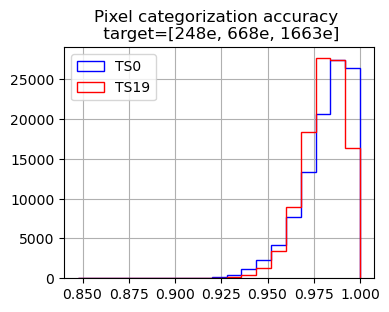

In [41]:
fig, ax = plt.subplots(1,1, figsize = (4,3))
print(ts1acc.shape)
globalmin = min(min(ts0acc),min(ts19acc))
bins = np.linspace(globalmin, 1, 20)
ax.hist(ts0acc, histtype = 'step', bins = bins, color = 'blue')
ax.hist(ts19acc, histtype = 'step', bins = bins, color = 'red')
ax.grid()
ax.set_title("Pixel categorization accuracy \n target=[248e, 668e, 1663e]")
plt.legend(["TS0", "TS19"])

for value in range(4):
    print(value)
    vmask = true_clusters == value
    # print(vmask.shape, vmask)
    

(100, 16, 16, 2)
input_1
input_1
4/4 [==============================] - 0s 1ms/step
soft_quantizer_output
soft_quantizer_output
4/4 [==============================] - 0s 1ms/step
q_separable_conv2d
q_separable_conv2d
4/4 [==============================] - 0s 2ms/step
q_activation
q_conv2d
q_conv2d
4/4 [==============================] - 0s 2ms/step
q_activation_1
average_pooling2d
average_pooling2d
4/4 [==============================] - 0s 2ms/step
q_activation_2
conv2d_transpose
conv2d_transpose
4/4 [==============================] - 0s 2ms/step
q_activation_3
conv2d_transpose_1
conv2d_transpose_1
4/4 [==============================] - 0s 2ms/step
q_activation_4
conv2d
conv2d
4/4 [==============================] - 0s 2ms/step
q_activation_5
flatten
dense
reshape
reshape
4/4 [==============================] - 0s 3ms/step
(100, 16, 16, 2)


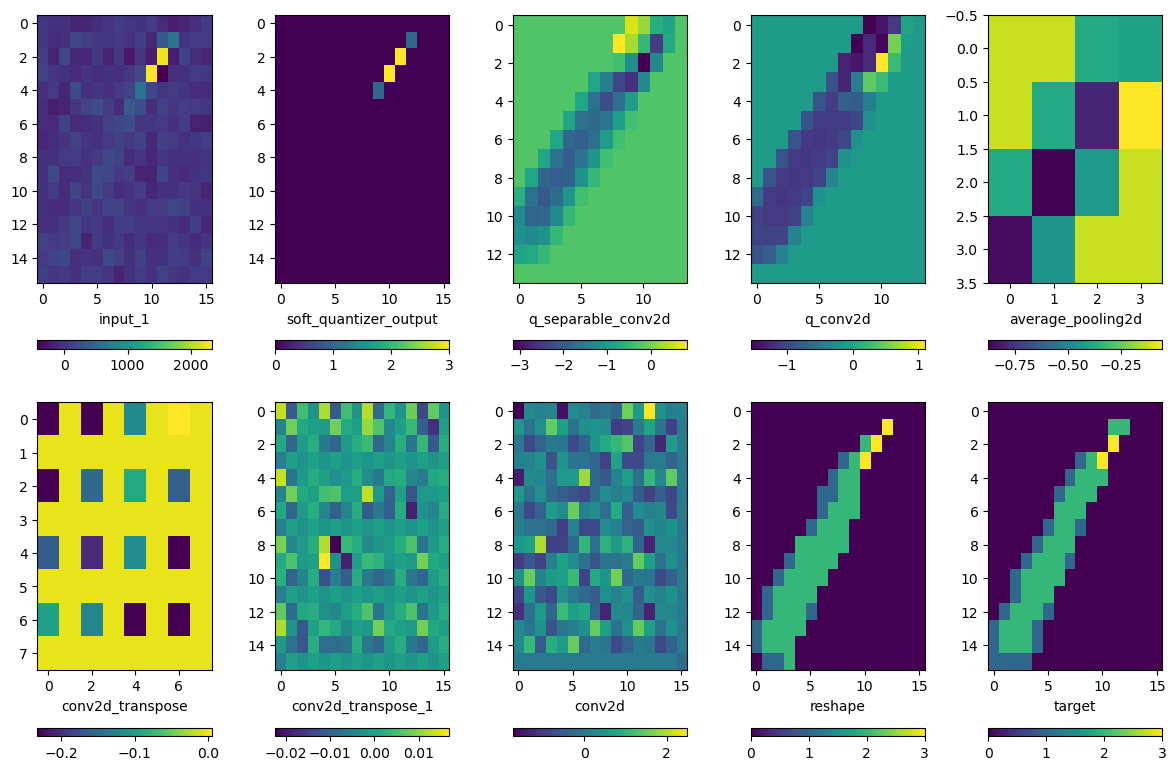

In [7]:
from keras import Model

N = 40
test_cluster = validation_generator[0][0][:100][:,:,:]
print(test_cluster.shape)
#indicies: batch_index, in/out, index_in_batch, {nxm pixels}, time slice

layer_substrings = ['inp','soft','conv', 'pool', 'samp', 'lamb', 'reshape', #'activ'
                   ]

kernel = 0
ts = 0


# for k in range(8):
i=0
fig, ax = plt.subplots(2, 5, figsize=(12, 8))
ax = ax.flatten()
for layer in model.layers:
    print(layer.name)
    if any(substring in layer.name for substring in layer_substrings):
        print(layer.name)
        layer_name =layer.name
        int_model = Model(inputs=model.input, outputs=model.get_layer(layer_name).output)
        out = int_model.predict(test_cluster)
        if 'reshape' in layer_name:
            out = np.argmax(out, axis =-1)
            print(out.shape)
        if len(out[N][0,0,:])>2:
            cluster = out[N][:,:, kernel]
        else:
            cluster = out[N][:,:,ts]
        a = ax[i].imshow(cluster, aspect='auto') #vmin = -5000, vmax = 100000,
        ax[i].set(xlabel = layer_name)
        fig.colorbar(a, orientation = 'horizontal',)
        i+=1
        # plt.colorbar(a)
    else: 
        continue
logmin,logmax = -12.465420526441807, 16.62130959403679
target_cluster = validation_generator[0][1][:100][:,:,:]
# target_cluster = log_scale(target_cluster)
# target_cluster = asymmetric_scaling(target_cluster, pos_scale = logmax, neg_scale = abs(logmin))
# print(target_cluster[N][:,:,ts])
a = ax[i].imshow(np.argmax(target_cluster[N][:,:,ts], axis = -1), aspect='auto') #vmin = -5000, vmax = 100000,
ax[i].set(xlabel = 'target')
fig.colorbar(a, orientation = 'horizontal',)
fig.tight_layout()


Index(['epoch', 'k', 'level_0', 'level_1', 'level_2', 'level_3', 'threshold_0',
       'threshold_1', 'threshold_2', 'raw_first_level',
       'raw_log_level_delta_0', 'raw_log_level_delta_1',
       'raw_log_level_delta_2', 'raw_first_threshold'],
      dtype='object')


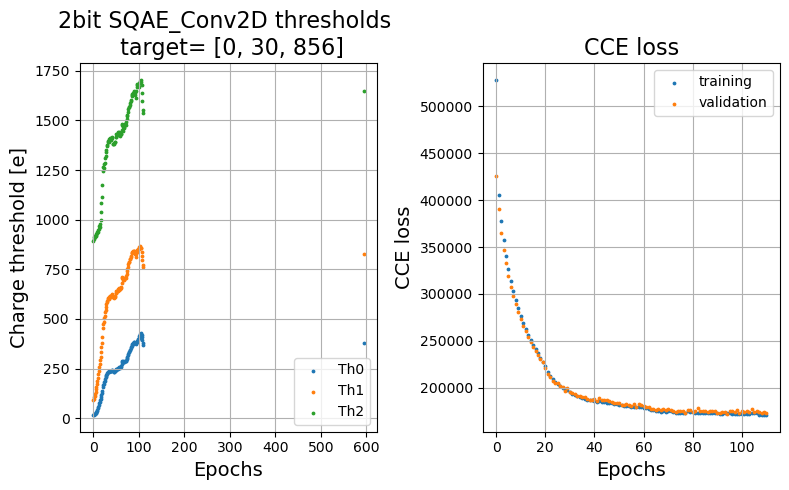

In [10]:
'''Threshold migration and loss optimization for one training'''
SQ_log = pd.read_csv(os.path.join(weights_path, 'soft_quantizer_state_log.csv'))
print(SQ_log.columns)

th_keys = [f'threshold_{i}' for i in range(3)]

fig, ax = plt.subplots(1,2, figsize = (8,5))
for i, th_key in enumerate(th_keys):
    epochs = SQ_log['epoch']
    th_charge = SQ_log[th_key]
    ax[0].scatter(epochs, th_charge, s=3, label = f'Th{i}')

ax[0].grid()
ax[0].legend()
ax[0].set_xlabel('Epochs', fontsize =14)
ax[0].set_ylabel('Charge threshold [e]', fontsize = 14)
ax[0].set_title('2bit SQAE_Conv2D thresholds \n target= [0, 30, 856]', #[0, 7, 23, 134, 404, 867, 1748]', #[0, 30, 856]', #[0, 7, 23, 134, 404, 867, 1748]', #0_30_856
                fontsize = 16)


# checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
# latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
training_cp_path = os.path.join(weights_path, 'training_log.csv')
training_history = pd.read_csv(training_cp_path)

ax[1].scatter(training_history['epoch'], training_history['loss'], s=3)
ax[1].scatter(training_history['epoch'], training_history['val_loss'], s=3)
ax[1].legend(['training', 'validation'])
ax[1].grid(True)
ax[1].set_xlabel('Epochs', fontsize = 14)
ax[1].set_title('CCE loss', fontsize = 16)
ax[1].set_ylabel('CCE loss', fontsize = 14)

fig.tight_layout()

# fig.savefig('ThresholdMigration_Categorical_3bit_80eN_Target_0_7_23_134_404_867_1748.png' #0_30_856.png
#            )
    

In [15]:
from scipy.optimize import curve_fit

def gauss(x, A, mu, sigma):
    return A * np.exp(-(x - mu) ** 2 / (2 * sigma ** 2))

def pull_plot(ax, var, name, label, p=0):
    
    h = ax.hist(df[var],bins=np.linspace(-5,5,50),histtype='step', label=label)
    ax.set_xlabel(name)
    ax.set_yscale('log')

    ydata = h[0]
    xdata = h[1][:-1]+3/50.

    pars, cov = curve_fit(gauss,xdata,ydata)

    xbins = np.linspace(-5,5,100)
    ax.plot(xbins,gauss(xbins,pars[0],pars[1],pars[2]),color='black')
    ax.set_ylim(0.5,100000)

    print('Mean',pars[1])
    print('Sigma',pars[2])

    if p:
        ax.text(-1,25,"$\mu$="+str(round(pars[1],2)))
        ax.text(-1,10,"$\sigma$="+str(round(abs(pars[2]),2)))

def residual_plot(ax, thisdf, var1, var2, name, label, scaling=1.0,color = 'blue'):
    
    nbins = 15
    
    var1_scaled = thisdf[var1] * scaling
    var2_scaled = thisdf[var2] * scaling
    residual_scaled = var1_scaled - var2_scaled
    
    xmin = np.min(var1_scaled)
    xmax = np.max(var1_scaled)
    
    step = 1.0*(xmax-xmin)/nbins
    
    x = sns.regplot(x=var1_scaled, y=residual_scaled, x_bins=np.linspace(xmin,xmax,nbins), fit_reg=None, marker='.', ax=ax, label=label, color = color)
    ax.set_xlabel('True ' + name)
    ax.set_ylabel('True - predicted ' + name)
    
    thisdf['residual'+var2] = residual_scaled
    # print(var1)
    
    means = []
    upbar = []
    downbar = []
    for i in range(0,nbins):
        means += [np.mean(thisdf['residual'+var2][(var1_scaled>xmin + i*step) & (var1_scaled<xmin + (i+1)*step)])]
        upbar += [means[i] + np.mean(thisdf['sigma'+var2][(var1_scaled>xmin + i*step) & (var1_scaled<xmin + (i+1)*step)] * scaling)]
        downbar += [means[i] - np.mean(thisdf['sigma'+var2][(var1_scaled>xmin + i*step) & (var1_scaled<xmin + (i+1)*step)] * scaling)]
    ax.fill_between(x=np.linspace(xmin,xmax,nbins),y1=upbar,y2=downbar, alpha=0.2, color = color)
    print(f"{name} spread: ",np.mean(np.array(upbar)-np.array(downbar)))
    
def inverse_cot(cota):
    a = np.arctan(1.0/cota)
    a[np.where(a<0)] = a[np.where(a<0)] + pi
    return a    

def residual_plot_deg(ax, thisdf, var1, var2, name, label, scaling=1.0, color = 'blue'):
    # positions
    if 'cot' not in var1:
        residual_plot(ax, thisdf, var1, var2, name, label=label, scaling=scaling)
        return

    thisdf['angle'] = inverse_cot(thisdf[var2].values * scaling)*180/pi
    
    thisdf['angleup'] = abs(inverse_cot((thisdf[var2].values + thisdf['sigma'+var2].values) * scaling)*180/pi - thisdf['angle'])
    thisdf['angledown'] = abs(inverse_cot((thisdf[var2].values - thisdf['sigma'+var2].values) * scaling)*180/pi - thisdf['angle'])
    thisdf['angletrue'] = inverse_cot(thisdf[var1].values * scaling)*180/pi
        
    var1 = 'angletrue'
    var2 = 'angle'
    
    nbins = 15
    xmin = np.min(thisdf[var1])
    xmax = np.max(thisdf[var1])
    
    step = 1.0*(xmax-xmin)/nbins
        
    x = sns.regplot(x=thisdf[var1], y=(thisdf[var1]-thisdf[var2]), x_bins=np.linspace(xmin,xmax,nbins), fit_reg=None, marker='.', ax=ax, label=label, color = color)
    ax.set_xlabel('True ' + name)
    ax.set_ylabel('True - predicted ' + name)
    
    thisdf['residual'+var2] = (thisdf[var1]-thisdf[var2])
    # print(var1)
    
    means = []    
    upbar = []
    downbar = []
    for i in range(0,nbins):
        means += [np.mean(thisdf['residual'+var2][(thisdf[var1]>xmin + i*step) & (thisdf[var1]<xmin + (i+1)*step)])]
        upbar += [means[i] + np.mean(thisdf['angleup'][(thisdf[var1]>xmin + i*step) & (thisdf[var1]<xmin + (i+1)*step)])]
        downbar += [means[i] - np.mean(thisdf['angledown'][(thisdf[var1]>xmin + i*step) & (thisdf[var1]<xmin + (i+1)*step)])]
    #ax.scatter(x=np.linspace(xmin,xmax,nbins),y=means)
    ax.fill_between(x=np.linspace(xmin,xmax,nbins),y1=upbar,y2=downbar, alpha=0.2, color = color)
    print(f"{name} spread: ",np.mean(np.array(upbar)-np.array(downbar)))

Loading model from ./SQ_DAE_regression/model-7f27e133-SQDAE_regression_CategoricalLowThreshTarget-checkpoints/weights.748-t-23195.46-v-23761.68.hdf5
<class 'keras.engine.keras_tensor.KerasTensor'>
q_activation_146
Model: "model_44"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_20 (InputLayer)       [(None, 16, 16, 2)]       0         
                                                                 
 soft_quantizer_output (Soft  (None, 16, 16, 2)        4         
 QuantizeLayer)                                                  
                                                                 
 q_separable_conv2d_19 (QSep  (None, 16, 16, 5)        33        
 arableConv2D)                                                   
                                                                 
 q_activation_143 (QActivati  (None, 16, 16, 5)        0         
 on)                                      

21/21 [==============================] - 1s 55ms/step


100%|██████████| 21/21 [00:00<00:00, 23.58it/s]


CategoricalSQDAEregression_lowThreshTarget
$x$ [um] spread:  13.99413
$y$ [um] spread:  4.0986996


/tmp/ipykernel_571/3489528821.py:59: RuntimeWarning: divide by zero encountered in divide
  a = np.arctan(1.0/cota)


...

MaxConv2d_TransformerThresh
$x$ [um] spread:  17.881443
$y$ [um] spread:  4.002161


/tmp/ipykernel_571/3489528821.py:59: RuntimeWarning: divide by zero encountered in divide
  a = np.arctan(1.0/cota)


$\alpha$ [deg] spread:  27.602009


/tmp/ipykernel_571/3489528821.py:59: RuntimeWarning: divide by zero encountered in divide
  a = np.arctan(1.0/cota)


$\beta$ [deg] spread:  8.9048395


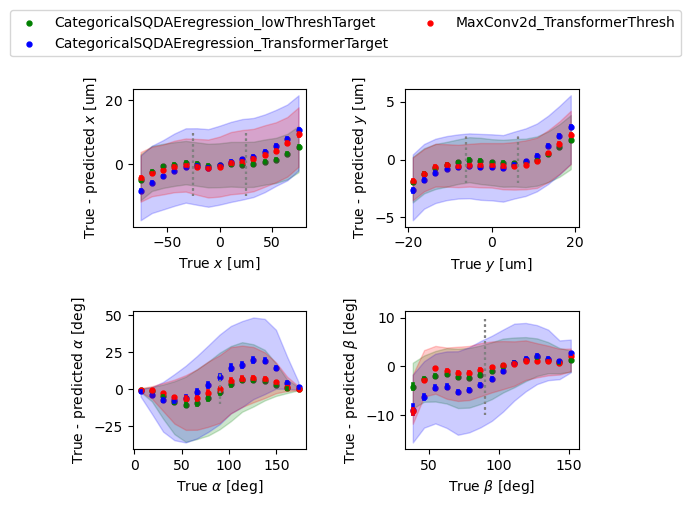

In [23]:
weights = [
            # './trained_models/model-aa3c9320-3src_2TS_OG-checkpoints',
            # './trained_models/model-e64ce838-3src_80eNoise-checkpoints',
            # './trained_models/model-c30dd8d2-3sr16x16__NoNoise-checkpoints/',
            # './trained_models/DAE_regression/model-b49a50a4-DAE_regression_64DecodeFilters_Dense16-checkpoints/',
            # './trained_models/model-1be2e7e1-400eThresh_80eNoise-checkpoints',
            # './SQ_DAE_regression/model-9017f974-SQDAE_regression-checkpoints/',
            # './SQ_DAE_regression/model-2e56fcfd-SQDAE_regression_80eThreshOffset-checkpoints/',
            './SQ_DAE_regression/model-7f27e133-SQDAE_regression_CategoricalLowThreshTarget-checkpoints/',
            './SQ_DAE_regression/model-93f43e96-SQDAE_regression_CategoricalTransformerTarget-checkpoints',

            '../smart-pixels-ml/trained_models/model-d2c7cac2-3sr16x16_opt2BitRaw_80eNoise-checkpoints/'
            
            # './trained_models/model-c8f8bb70-3sr16x16_2TS_80eNoise-checkpoints/',
          ]
tfrs = [
        # 'TFR_val/2TS_OG',
        # 'TFR_val/3src_80eNoise', 
        # "TFR_val/3sr_16x16_NoNoise",       
        # "TFR_val/3sr_16x16_80eNoise",
        # 'TFR_val/3sr_16x16_80eN_400eT',
        'TFR_val/3sr_16x16_80eN_raw',
        'TFR_val/3sr_16x16_80eN_raw',
        'TFR_val/3sr_16x16_Opt2bit'
        # "TFR_val/3sr_16x16_80eNoise",
        ]
SQ = [True,True,
      False, 
     ]
labels = [
          # 'No Noise', 
          # 'SQDAEregression 0eOffset', 'SQDAEregression 80eOffset',
          'CategoricalSQDAEregression_lowThreshTarget','CategoricalSQDAEregression_TransformerTarget',
          'MaxConv2d_TransformerThresh'
          # 'DAE-16Dense_64DecodeFilters',
          # '80e Noise + 400e Thresh', 
          # '80e Noise', 
          # ,
          # 'DAE-Dense 32', 'DAE-Dense 64'
          ]
colors = ['green', 'blue', 'red']

# p=[0,1]

nl = int(len(weights))

# fig, axes = plt.subplots(2,2,sharex=True,sharey=True,figsize=(6,5))
fig1, axes1 = plt.subplots(2,2,figsize=(6,5))
# fig1, axes1 = plt.subplots(1, 1, figsize=(5,4))
fig1.tight_layout(pad=4.0)

for i in range(nl):
    # base_dir = f'./weights-200ps_'+str(t0)
    base_dir = weights[i]
    checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
    latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
    #training_cp_path = os.path.join(base_dir, 'training_log.csv')
    #training_history = pd.read_csv(training_cp_path)
    print(f"Loading model from {latest_checkpoint}")

    if SQ[i]:
        DAE=CreateSQAutoEncoder((16,16,2), n_filters=5, pool_size=2, conv_kernel_size = 3, 
                        decoder_filters = 128, 
                        xrange = None
                       )
        layer_name = DAE.layers[9].name
        print(layer_name)
        encoder = Model(inputs=DAE.input, outputs=DAE.get_layer(layer_name).output)
        encoder.trainable = False
        x_in = encoder.input
        lat_shape = encoder.output.shape
        dense_net = var_network(encoder.output, hidden=16, output=14)
        model = Model(inputs=x_in, outputs=dense_net)
    else:
        model=CreateModel((16,16,2),n_filters=5,pool_size=3,conv_kernel_size=3
                          # mean_filter=mean_filter[i], thresh = thresh[i]
                         )

    model.load_weights(latest_checkpoint)
    model.summary()
    
    tfrecords_dir_val = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/"+tfrs[i]
    test_generator = NewDG(
        load_from_tfrecords_dir = tfrecords_dir_val,
    )
    # print(test_generator[0][0][:,:,:])

    # predicts test data
    p_test = model.predict(test_generator)
    
    complete_truth = None
    for _, y in tqdm(test_generator):
            if complete_truth is None:
                complete_truth = y
            else:
                complete_truth = np.concatenate((complete_truth, y), axis=0)
    
    # creates df with all predicted values and matrix elements - 4 predictions, all 10 unique matrix elements
    df = pd.DataFrame(p_test,columns=['x','M11','y','M22','cotA','M33','cotB','M44','M21','M31','M32','M41','M42','M43'])

    # df['x'] = df['x']*75.0
    # df['y'] = df['y']*18.75
    
    # stores all true values in same matrix as xtrue, ytrue, etc.
    df['xtrue'] = complete_truth[:,0]
    df['ytrue'] = complete_truth[:,1]
    df['cotAtrue'] = complete_truth[:,2]
    df['cotBtrue'] = complete_truth[:,3]
    df['M11'] = minval+tf.math.maximum(df['M11'], 0)
    df['M22'] = minval+tf.math.maximum(df['M22'], 0)
    df['M33'] = minval+tf.math.maximum(df['M33'], 0)
    df['M44'] = minval+tf.math.maximum(df['M44'], 0)
    
    df['sigmax'] = abs(df['M11'])
    df['sigmay'] = np.sqrt(df['M21']**2 + df['M22']**2)
    df['sigmacotA'] = np.sqrt(df['M31']**2+df['M32']**2+df['M33']**2)
    df['sigmacotB'] = np.sqrt(df['M41']**2+df['M42']**2+df['M43']**2+df['M44']**2)
    
    # calculates residuals for x, y, cotA, cotB
    residuals = df['xtrue'] - df['x']
    residualsy = df['ytrue'] - df['y']
    residualsA = df['cotAtrue'] - df['cotA']
    residualsB = df['cotBtrue'] - df['cotB']
    
    df['pullx'] = (df['xtrue']-df['x'])/df['sigmax']
    df['pully'] = (df['ytrue']-df['y'])/df['sigmay']
    df['pullcotA'] = (df['cotAtrue']-df['cotA'])/df['sigmacotA']
    df['pullcotB'] = (df['cotBtrue']-df['cotB'])/df['sigmacotB']

    ### Residual Plots ###
    print(labels[i])
    residual_plot(axes1[0][0],df,'xtrue','x',r'$x$ [um]', labels[i], scaling=75.0, color = colors[i])
    axes1[0][0].plot([-25,-25],[-10,10],color='gray',linestyle=':')
    axes1[0][0].plot([25,25],[-10,10],color='gray',linestyle=':')
    residual_plot(axes1[0][1],df,'ytrue','y',r'$y$ [um]', labels[i], scaling=18.75, color = colors[i])
    axes1[0][1].plot([-6.25,-6.25],[-2,2],color='gray',linestyle=':')
    axes1[0][1].plot([6.25,6.25],[-2,2],color='gray',linestyle=':')
    residual_plot_deg(axes1[1][0],df,'cotAtrue','cotA',r'$\alpha$ [deg]', labels[i], scaling=8.0, color = colors[i])
    axes1[1][0].plot([90,90],[-10,10],color='gray',linestyle=':')
    residual_plot_deg(axes1[1][1],df,'cotBtrue','cotB',r'$\beta$ [deg]', labels[i], scaling=1.7, color = colors[i])
    axes1[1][1].plot([90,90],[-10,10],color='gray',linestyle=':')    
    save_fig_path = os.path.join(base_dir, 'summary1.png')
    
    # residual_plot_deg(axes1,df,'cotAtrue','cotA',r'$\alpha$ [deg]', labels[i], scaling=8.0)
    # axes1.plot([90,90],[-10,10],color='gray',linestyle=':')
# print("done!")
nl = int(len(weights))
lines_labels = [ax.get_legend_handles_labels() for ax in fig1.axes]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)]
lgd = fig1.legend(lines[:nl], labels[:nl], bbox_to_anchor=(0.5, 1.05), loc='upper center', ncol=2)
plt.savefig(save_fig_path, bbox_extra_artists=(lgd,), bbox_inches='tight')
